# 🕸️ Network Graph Representation EDA & Graph Feature Engineering
**Mengapa Network Graph Representation Sangat Penting di GEMASTIK Data Mining?**
- Sebagian besar tim hanya menampilkan *WordCloud* atau *Bar Chart* frekuensi kata saat presentasi final.
- Dengan **Network Graph Representation**, tim Anda dapat:
  1. **Visualisasi Babak Final (Bobot 50% Metode & Presentasi):** Memetakan **Word/Entity Co-occurrence Graph** untuk memperlihatkan *Hub Words* (kata pusat topik) dan *Bridge Words* (kata penghubung antar sentimen/isu).
  2. **Deteksi Anomali & Homofili Dokumen ($k$-NN Document Graph):** Melihat apakah dokumen dengan label yang sama saling mengelompok (*homophily*) atau ada sampel *noisy label* yang terisolasi.
  3. **Graph Feature Engineering (Penambah Skor F1):** Mengekstrak fitur **Document PageRank**, **Mean Keyword Degree Centrality**, serta **Out-of-Fold Graph Neighbor Target Mean (`graph_oof_neighbor_prob_*`)** untuk disuntikkan ke LightGBM!

In [1]:
# ==============================================================================
# ⚙️ MASTER USER CONFIGURATION (PUSAT KENDALI NETWORK GRAPH EDA & FEATURES)
# ==============================================================================
TRAIN_PATH           = '../demo_data/train_chained_soal2.csv'
TEST_PATH            = '../demo_data/test_chained_soal2.csv'
TEXT_COL             = 'text'
TARGET_COL           = 'soal2_action_target'

TOP_VOCAB_NODES      = 28          # Jumlah kata teratas untuk Word Co-occurrence Graph
WINDOW_SIZE          = 4           # Jarak maksimum kata dalam 1 sliding window co-occurrence
KNN_NEIGHBORS        = 5           # Jumlah tetangga terdekat pada Document Similarity Graph
EVAL_METRIC          = 'macro_f1'
SEED                 = 42
print('✅ Konfigurasi Network Graph Representation EDA berhasil dimuat!')

✅ Konfigurasi Network Graph Representation EDA berhasil dimuat!


In [2]:
import json
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb

from smart_loader import load_raw_format_to_df, evaluate_classification_switchboard
from indonesian_regex_combinator import IndonesianRegexCombinator

MODELS_DIR = Path('models')
MODELS_DIR.mkdir(parents=True, exist_ok=True)

train_df = load_raw_format_to_df(TRAIN_PATH)
test_df  = load_raw_format_to_df(TEST_PATH)

combinator = IndonesianRegexCombinator(remove_stopwords_negation_safe=True)
train_df['clean_text'] = [combinator.clean_text(t) for t in train_df[TEXT_COL]]
test_df['clean_text']  = [combinator.clean_text(t) for t in test_df[TEXT_COL]]
print(f'📂 Data dimuat: {len(train_df)} train | {len(test_df)} test')

📂 Data dimuat: 72 train | 24 test


C:\Users\yasse\AppData\Local\Temp\ipykernel_38404\2423529265.py:64: UserWarning: Glyph 128376 (\N{SPIDER WEB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yasse\AppData\Local\Temp\ipykernel_38404\2423529265.py:64: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yasse\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128376 (\N{SPIDER WEB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\yasse\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


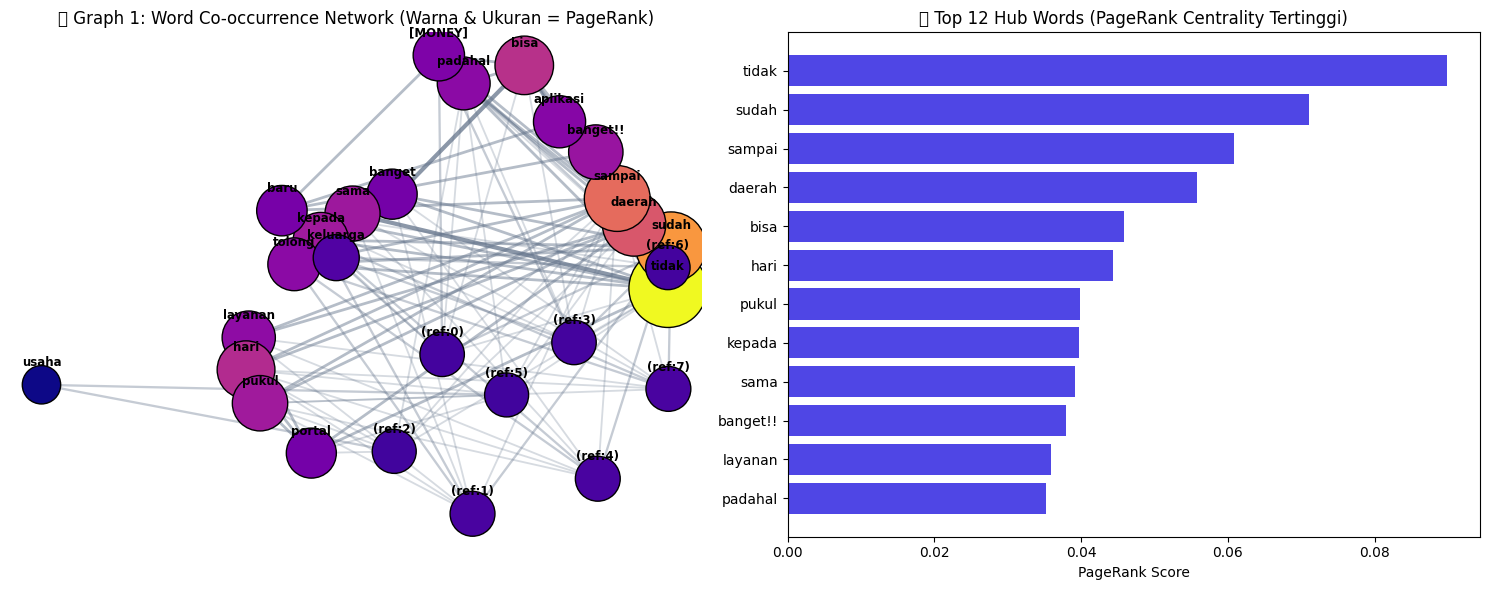

In [3]:
# ==============================================================================
# 🕸️ GRAPH 1: WORD CO-OCCURRENCE NETWORK & PAGE-RANK CENTRALITY
# ==============================================================================
# Hitung frekuensi kata & matriks ko-okurensi (sliding window)
token_lists = [
    [w for w in t.split() if len(w) > 2 and not w.startswith('<')]
    for t in train_df['clean_text']
]
word_freq = Counter(w for toks in token_lists for w in toks)
top_words = [w for w, _ in word_freq.most_common(TOP_VOCAB_NODES)]
word2idx = {w: i for i, w in enumerate(top_words)}

adj_cooc = np.zeros(( len(top_words), len(top_words) ), dtype=np.float32)
for toks in token_lists:
    filtered = [w for w in toks if w in word2idx]
    for i in range(len(filtered)):
        for j in range(i + 1, min(i + WINDOW_SIZE, len(filtered))):
            u, v = word2idx[filtered[i]], word2idx[filtered[j]]
            if u != v:
                adj_cooc[u, v] += 1.0
                adj_cooc[v, u] += 1.0

# Hitung Power-Iteration PageRank & Degree Centrality untuk setiap kata
deg = adj_cooc.sum(axis=1)
transition = adj_cooc / np.maximum(deg[:, None], 1e-8)
pagerank = np.ones(len(top_words), dtype=np.float32) / max(1, len(top_words))
for _ in range(30):
    pagerank = 0.15 / max(1, len(top_words)) + 0.85 * (transition.T @ pagerank)

word_pr_map = {w: float(pagerank[i]) for i, w in enumerate(top_words)}
word_deg_map = {w: float(deg[i] / max(1.0, deg.max())) for i, w in enumerate(top_words)}

# Visualisasi Graph 1 (Fruchterman-Reingold Spectral/Spring Layout dengan Matplotlib Murni)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Spectral layout 2D dari matriks Laplacian Ko-okurensi
laplacian = np.diag(deg) - adj_cooc
eigvals, eigvecs = np.linalg.eigh(laplacian)
coords = eigvecs[:, 1:3] if eigvecs.shape[1] >= 3 else np.random.randn(len(top_words), 2)
# Tambahkan jitter radial lembut agar label kata mudah dibaca
angles = np.linspace(0, 2 * np.pi, len(top_words), endpoint=False)
coords = 0.65 * coords + 0.35 * np.column_stack([np.cos(angles), np.sin(angles)])

ax = axes[0]
max_w = max(1.0, adj_cooc.max())
for i in range(len(top_words)):
    for j in range(i + 1, len(top_words)):
        if adj_cooc[i, j] >= 2.0:
            alpha = min(0.75, 0.15 + 0.65 * (adj_cooc[i, j] / max_w))
            ax.plot([coords[i, 0], coords[j, 0]], [coords[i, 1], coords[j, 1]], color='#64748b', alpha=alpha, lw=1.0 + 2.0*(adj_cooc[i, j]/max_w))

node_sizes = 350 + 2800 * (pagerank / max(1e-8, pagerank.max()))
sc = ax.scatter(coords[:, 0], coords[:, 1], s=node_sizes, c=pagerank, cmap='plasma', edgecolors='black', zorder=3)
for i, w in enumerate(top_words):
    ax.text(coords[i, 0], coords[i, 1] + 0.04, w, fontsize=8.5, fontweight='bold', ha='center', zorder=4)
ax.set_title('🕸️ Graph 1: Word Co-occurrence Network (Warna & Ukuran = PageRank)')
ax.axis('off')

# Bar chart Top 12 Hub Words berdasarkan PageRank Centrality
top_pr_pairs = sorted(word_pr_map.items(), key=lambda x: x[1], reverse=True)[:12]
axes[1].barh([p[0] for p in reversed(top_pr_pairs)], [p[1] for p in reversed(top_pr_pairs)], color='#4f46e5')
axes[1].set_title('🏆 Top 12 Hub Words (PageRank Centrality Tertinggi)')
axes[1].set_xlabel('PageRank Score')
plt.tight_layout()
plt.show()

In [4]:
# ==============================================================================
# 🕸️ GRAPH 2 & 3: DOCUMENT k-NN HOMOPHILY GRAPH + GRAPH FEATURE ENGINEERING
# ==============================================================================
# Bangun k-NN Document Similarity Graph & ekstrak fitur Graph untuk GBDT:
#   1. graph_doc_pagerank_mean : Rata-rata PageRank kata di dalam dokumen
#   2. graph_doc_degree_max    : Degree centrality maksimum kata di dalam dokumen
#   3. graph_knn_mean_sim      : Rata-rata kemiripan dokumen ke K tetangga terdekat (deteksi outlier)
#   4. graph_oof_neighbor_prob : Distribusi label dari K tetangga terdekat (Out-Of-Fold, bebas bocor!)

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=2000, sublinear_tf=True)
X_tr_tfidf = tfidf.fit_transform(train_df['clean_text'])
X_te_tfidf = tfidf.transform(test_df['clean_text'])

classes = sorted(train_df[TARGET_COL].unique())
label2id = {c: i for i, c in enumerate(classes)}
y_train = train_df[TARGET_COL].map(label2id).values

def compute_word_centrality_features(texts):
    feats = []
    for t in texts:
        toks = [w for w in str(t).split() if w in word_pr_map]
        if toks:
            pr_vals = [word_pr_map[w] for w in toks]
            dg_vals = [word_deg_map[w] for w in toks]
            feats.append([np.mean(pr_vals), np.max(pr_vals), np.mean(dg_vals), np.max(dg_vals)])
        else:
            feats.append([0.0, 0.0, 0.0, 0.0])
    return np.array(feats, dtype=np.float32)

tr_word_graph_feats = compute_word_centrality_features(train_df['clean_text'])
te_word_graph_feats = compute_word_centrality_features(test_df['clean_text'])

# Out-of-Fold Document k-NN Neighbor Target Distribution
sim_tr_tr = cosine_similarity(X_tr_tfidf, X_tr_tfidf)
np.fill_diagonal(sim_tr_tr, -1.0)

oof_neighbor_probs = np.zeros((len(train_df), len(classes)), dtype=np.float32)
tr_knn_mean_sim = np.zeros((len(train_df), 1), dtype=np.float32)

for i in range(len(train_df)):
    top_k_idx = np.argsort(sim_tr_tr[i])[::-1][:KNN_NEIGHBORS]
    sims = np.maximum(sim_tr_tr[i, top_k_idx], 1e-4)
    tr_knn_mean_sim[i, 0] = float(np.mean(sims))
    for neighbor_idx, s_val in zip(top_k_idx, sims):
        oof_neighbor_probs[i, y_train[neighbor_idx]] += float(s_val)
    oof_neighbor_probs[i] /= max(1e-6, oof_neighbor_probs[i].sum())

sim_te_tr = cosine_similarity(X_te_tfidf, X_tr_tfidf)
te_neighbor_probs = np.zeros((len(test_df), len(classes)), dtype=np.float32)
te_knn_mean_sim = np.zeros((len(test_df), 1), dtype=np.float32)
for i in range(len(test_df)):
    top_k_idx = np.argsort(sim_te_tr[i])[::-1][:KNN_NEIGHBORS]
    sims = np.maximum(sim_te_tr[i, top_k_idx], 1e-4)
    te_knn_mean_sim[i, 0] = float(np.mean(sims))
    for neighbor_idx, s_val in zip(top_k_idx, sims):
        te_neighbor_probs[i, y_train[neighbor_idx]] += float(s_val)
    te_neighbor_probs[i] /= max(1e-6, te_neighbor_probs[i].sum())

# Benchmark: Model Tanpa Graph Features vs Dengan Graph Features
from scipy.sparse import hstack, csr_matrix
X_tr_with_graph = hstack([X_tr_tfidf, csr_matrix(np.hstack([tr_word_graph_feats, tr_knn_mean_sim, oof_neighbor_probs]))]).tocsr()

skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
oof_base = np.zeros((len(train_df), len(classes)))
oof_graph = np.zeros((len(train_df), len(classes)))

for fold, (tr_i, val_i) in enumerate(skf.split(train_df, y_train)):
    m_base = lgb.LGBMClassifier(n_estimators=80, max_depth=3, learning_rate=0.05, random_state=SEED+fold, verbose=-1)
    m_base.fit(X_tr_tfidf[tr_i], y_train[tr_i])
    oof_base[val_i] = m_base.predict_proba(X_tr_tfidf[val_i])

    m_graph = lgb.LGBMClassifier(n_estimators=80, max_depth=3, learning_rate=0.05, random_state=SEED+fold, verbose=-1)
    m_graph.fit(X_tr_with_graph[tr_i], y_train[tr_i])
    oof_graph[val_i] = m_graph.predict_proba(X_tr_with_graph[val_i])
    m_graph.booster_.save_model(str(MODELS_DIR / f'graph_enhanced_lgb_fold{fold}.txt'))

score_base, _, rep_base = evaluate_classification_switchboard(
    y_true=y_train,
    y_pred_labels=np.argmax(oof_base, axis=1),
    y_prob=oof_base,
    primary_metric=EVAL_METRIC,
)
score_graph, _, rep_graph = evaluate_classification_switchboard(
    y_true=y_train,
    y_pred_labels=np.argmax(oof_graph, axis=1),
    y_prob=oof_graph,
    primary_metric=EVAL_METRIC,
)

meta_payload = {
    'notebook': '03_network_graph_representation_eda',
    'baseline_macro_f1': float(score_base),
    'graph_enhanced_macro_f1': float(score_graph),
    'all_validation_metrics': {k: float(v) for k, v in rep_graph.items() if isinstance(v, (int, float))},
}
with open(MODELS_DIR / '03_graph_features_config_results.json', 'w', encoding='utf-8') as f:
    json.dump(meta_payload, f, indent=2)

print(f"\n🚀 Perbandingan Skor {EVAL_METRIC}: Baseline TF-IDF = {score_base:.5f} -> +Graph Features = {score_graph:.5f}")


🚀 Perbandingan Skor macro_f1: Baseline TF-IDF = 0.80615 -> +Graph Features = 0.88677


C:\Users\yasse\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\yasse\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\yasse\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\yasse\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\yasse\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LG